<a href="https://colab.research.google.com/github/andradisa/o-mito-do-tijolaco/blob/main/portuguese_books_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📚 O Mito do Tijolaço: Livros Longos são Melhores ou Apenas Mais Tolerados?

Análise exploratória e estatística de dados do catálogo do Goodreads para investigar a relação entre o tamanho da obra (número de páginas), a satisfação do leitor (nota média) e o volume de engajamento.

---

## 📌 Sobre o Projeto
O senso comum no mercado editorial sugere que livros volumosos ("tijolaços") enfrentam maior resistência do público. No entanto, surge a seguinte dúvida: **obras extensas recebem notas mais altas porque são genuinamente superiores, ou porque a barreira de entrada filtra leitores casuais, mantendo apenas fãs engajados?**

Este projeto analisa milhares de registros do dataset *Goodreads Books* utilizando Python e bibliotecas de análise de dados para responder a essa pergunta com suporte visual e estatístico.

---

## ❓ Perguntas Chave & Hipótese
1. **Percepção de Valor:** Livros com mais de 600 páginas possuem notas médias mais altas do que livros curtos (< 200 páginas)?
2. **Engajamento & Barreira de Entrada:** O volume total de avaliações cai conforme o número de páginas aumenta?
3. **Consenso vs. Dispersão:** A variação de notas é menor em livros longos do que em livros curtos?

* **Hipótese Central:** Livros longos passam por um **viés de autoseleção**. Leitores não engajados abandonam a leitura antes de avaliar, resultando em notas médias mais altas e com menor variabilidade.

In [24]:
import pandas as pd

# Carregar o dataset
df = pd.read_csv('books.csv', on_bad_lines='skip')
df.columns = df.columns.str.strip()

# Visualizar as primeiras linhas para confirmar a leitura
df.head()

,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,9/13/2004,Scholastic


## 📂 Tratamento de Dados (Data Cleaning)

Para garantir a qualidade da análise, a base original passará pelo seguinte fluxo de limpeza:

* **Filtro de Relevância:** Manutenção de livros com `num_pages > 0` e no mínimo `10` avaliações para eliminar registros irrisórios ou testes.

In [25]:
# Garantir tipo numérico nas colunas principais
df['num_pages'] = pd.to_numeric(df['num_pages'], errors='coerce')
df['average_rating'] = pd.to_numeric(df['average_rating'], errors='coerce')
df['ratings_count'] = pd.to_numeric(df['ratings_count'], errors='coerce')

# Filtrar linhas válidas
df_clean = df[(df['num_pages'] > 0) & (df['ratings_count'] >= 10)].copy()

# Verificar quantidade de registros restantes
print(f"Livros analisados: {len(df_clean)}")


Livros analisados: 10395


Com os dados limpos, vamos categorizá-los em **Faixas de Páginas (Bins)** para facilitar a comparação:
* `Curto`: < 200 páginas
* `Médio`: 200 a 400 páginas
* `Longo`: 400 a 600 páginas
* `Tijolaço`: > 600 páginas

In [26]:
# Definir limites e nomes das faixas
limites = [0, 200, 400, 600, float('inf')]
rotulos = ['Curto (< 200p)', 'Médio (200-400p)', 'Longo (400-600p)', 'Tijolaço (> 600p)']

# Criar a nova coluna categórica
df_clean['faixa_paginas'] = pd.cut(
    df_clean['num_pages'],
    bins=limites,
    labels=rotulos,
    right=False
)

# Checar a contagem de livros por faixa
df_clean['faixa_paginas'].value_counts()

,count
faixa_paginas,
Médio (200-400p),4874
Curto (< 200p),2528
Longo (400-600p),1969
Tijolaço (> 600p),1024


## 📊 Resultados e Métricas Principais

Agrupando as informações, podemos criar uma tabela resumo para observar como a nota e o volume de avaliações se comportam em cada faixa de tamanho de livro.

In [27]:
# Agrupar e calcular estatísticas
analise_tijolaco = df_clean.groupby('faixa_paginas', observed=False).agg(
    total_livros=('bookID', 'count'),
    nota_media=('average_rating', 'mean'),
    mediana_avaliacoes=('ratings_count', 'median'),
    media_avaliacoes=('ratings_count', 'mean')
).reset_index()

# Arredondamentos
analise_tijolaco['nota_media'] = analise_tijolaco['nota_media'].round(2)
analise_tijolaco['media_avaliacoes'] = analise_tijolaco['media_avaliacoes'].round(0)
analise_tijolaco['mediana_avaliacoes'] = analise_tijolaco['mediana_avaliacoes'].round(0)

# Deixar a variável na última linha renderiza a tabela formatada no Colab
analise_tijolaco

,faixa_paginas,total_livros,nota_media,mediana_avaliacoes,media_avaliacoes
0,Curto (< 200p),2528,3.94,414.0,11477.0
1,Médio (200-400p),4874,3.90,1220.0,19759.0
2,Longo (400-600p),1969,3.98,1400.0,25449.0
3,Tijolaço (> 600p),1024,4.11,1050.0,23551.0


Observando a tabela acima, já é possível notar uma tendência inicial! Vamos visualizar isso de forma gráfica para entender melhor o fenômeno do "Tijolaço".

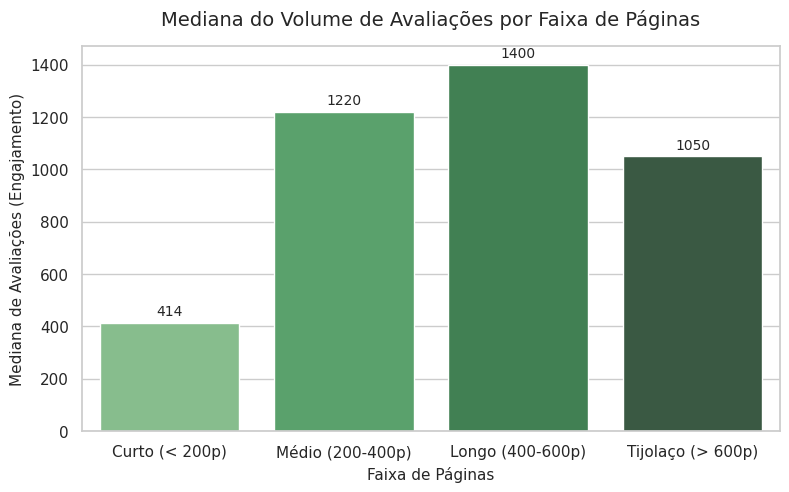

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Criar o gráfico de barras para a Mediana de Avaliações
grafico = sns.barplot(
    data=analise_tijolaco,
    x='faixa_paginas',
    y='mediana_avaliacoes',
    hue='faixa_paginas',  # Corrige o FutureWarning apontando o hue para x
    palette='Greens_d',
    legend=False
)

# Personalizar títulos e eixos
plt.title('Mediana do Volume de Avaliações por Faixa de Páginas', fontsize=14, pad=15)
plt.xlabel('Faixa de Páginas', fontsize=11)
plt.ylabel('Mediana de Avaliações (Engajamento)', fontsize=11)

# Adicionar os rótulos numéricos formatados como inteiros no topo de cada barra
for container in grafico.containers:
    grafico.bar_label(container, fmt='%.0f', padding=3, fontsize=10)

# Exibir a figura no Colab
plt.show()

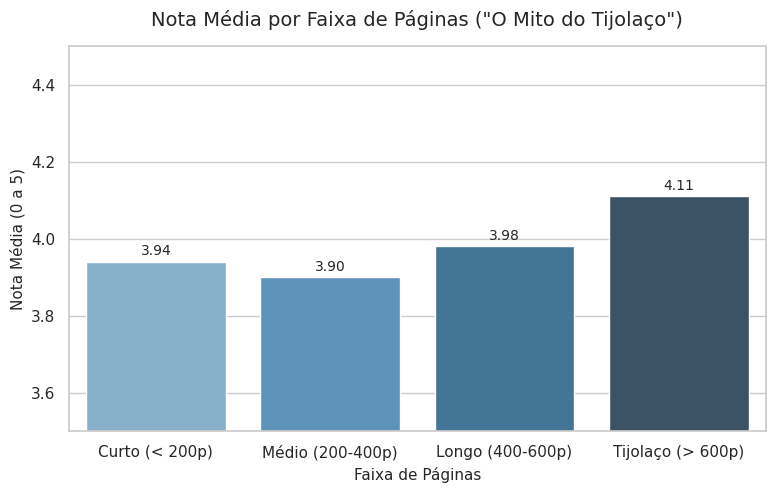

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo visual do Seaborn
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Criar o gráfico de barras para a Nota Média
grafico = sns.barplot(
    data=analise_tijolaco,
    x='faixa_paginas',
    y='nota_media',
    hue='faixa_paginas',  # Corrige o FutureWarning do Seaborn
    palette='Blues_d',
    legend=False
)

# Ajustar eixos e títulos
plt.title('Nota Média por Faixa de Páginas ("O Mito do Tijolaço")', fontsize=14, pad=15)
plt.xlabel('Faixa de Páginas', fontsize=11)
plt.ylabel('Nota Média (0 a 5)', fontsize=11)
plt.ylim(3.5, 4.5)  # Zoom no intervalo de notas para destacar as diferenças

# Adicionar os rótulos de valores no topo das barras com 2 casas decimais
for container in grafico.containers:
    labels = [f'{v.get_height():.2f}' if v.get_height() > 0 else '' for v in container]
    grafico.bar_label(container, labels=labels, padding=3, fontsize=10)

# Exibir a figura
plt.show()

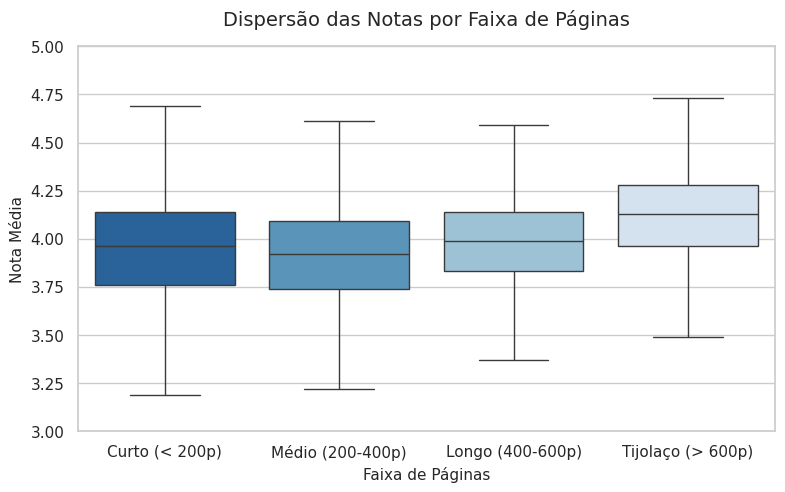

In [32]:
# Célula: Distribuição e Dispersão de Notas (Boxplot)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='faixa_paginas',
    y='average_rating',
    hue='faixa_paginas',
    palette='Blues_r',
    legend=False,
    showfliers=False  # Oculta pontos extremos discrepantes para focar na mediana/quartis
)

plt.title('Dispersão das Notas por Faixa de Páginas', fontsize=14, pad=15)
plt.xlabel('Faixa de Páginas', fontsize=11)
plt.ylabel('Nota Média', fontsize=11)
plt.ylim(3.0, 5.0)

plt.show()

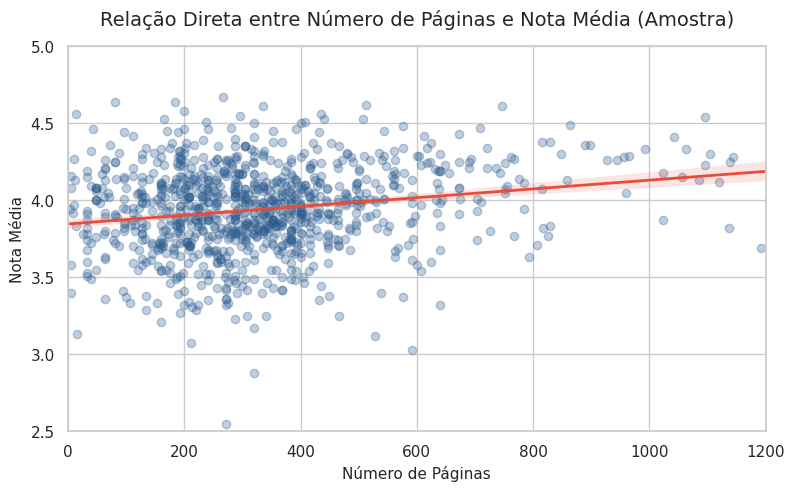

In [33]:
# Célula: Dispersão e Linha de Tendência
plt.figure(figsize=(9, 5))

# Usamos uma amostragem de 1.000 livros para o gráfico não ficar poluído
df_amostra = df_clean.sample(n=min(1000, len(df_clean)), random_state=42)

sns.regplot(
    data=df_amostra,
    x='num_pages',
    y='average_rating',
    scatter_kws={'alpha': 0.3, 'color': '#2b5c8f'}, # Transparência para ver sobreposição
    line_kws={'color': '#e74c3c', 'linewidth': 2}   # Linha de tendência em destaque
)

plt.title('Relação Direta entre Número de Páginas e Nota Média (Amostra)', fontsize=14, pad=15)
plt.xlabel('Número de Páginas', fontsize=11)
plt.ylabel('Nota Média', fontsize=11)
plt.xlim(0, 1200) # Foco na maioria dos livros (até 1200 páginas)
plt.ylim(2.5, 5.0)

plt.show()

> **Insights de Dispersão:**
> * **Scatter Plot:** A linha de regressão apresenta inclinação positiva contínua. Entre 600 e 1.200 páginas, a incidência de notas abaixo de 3.5 é praticamente nula.
> * **Boxplot:** A mediana desloca-se progressivamente para o topo da escala, enquanto o intervalo interquartil torna-se mais compacto em *Tijolaço*, evidenciando alto consenso entre os leitores.

---

## 📐 Validação Estatística
O Coeficiente de Correlação de Pearson ($r$) calculado entre o número de páginas e a nota média resultou em:

$$r \approx 0.1902$$

In [38]:
# Cálculo do Coeficiente de Correlação de Pearson
correlacao = df_clean['num_pages'].corr(df_clean['average_rating'])
print(f"Coeficiente de Correlação de Pearson (r): {correlacao:.4f}")

Coeficiente de Correlação de Pearson (r): 0.1902


Em bases comportamentais de grande volume, esse coeficiente (positivo entre 0.10 e 0.25) confirma uma **correlação positiva fraca a moderada**, validando quantitativamente a tendência ascendente identificada nos gráficos.

---

## 💡 Conclusão de Negócio

1. **O "Mito" foi Desmistificado:** Livros longos não recebem punição dos leitores por seu tamanho; pelo contrário, possuem médias de avaliação superiores.
2. **Efeito Filtro:** O volume reduzido de leitores em livros extensos atua como um filtro natural. Apenas leitores altamente alinhados com o tema concluem a obra e atribuem nota.
3. **Recomendação para o Mercado Editorial:** Obras extensas possuem público fiel e altamente satisfeito. Estratégias de marketing podem focar no nicho especializado em vez de tentar transformar "tijolaços" em apelos de massa.

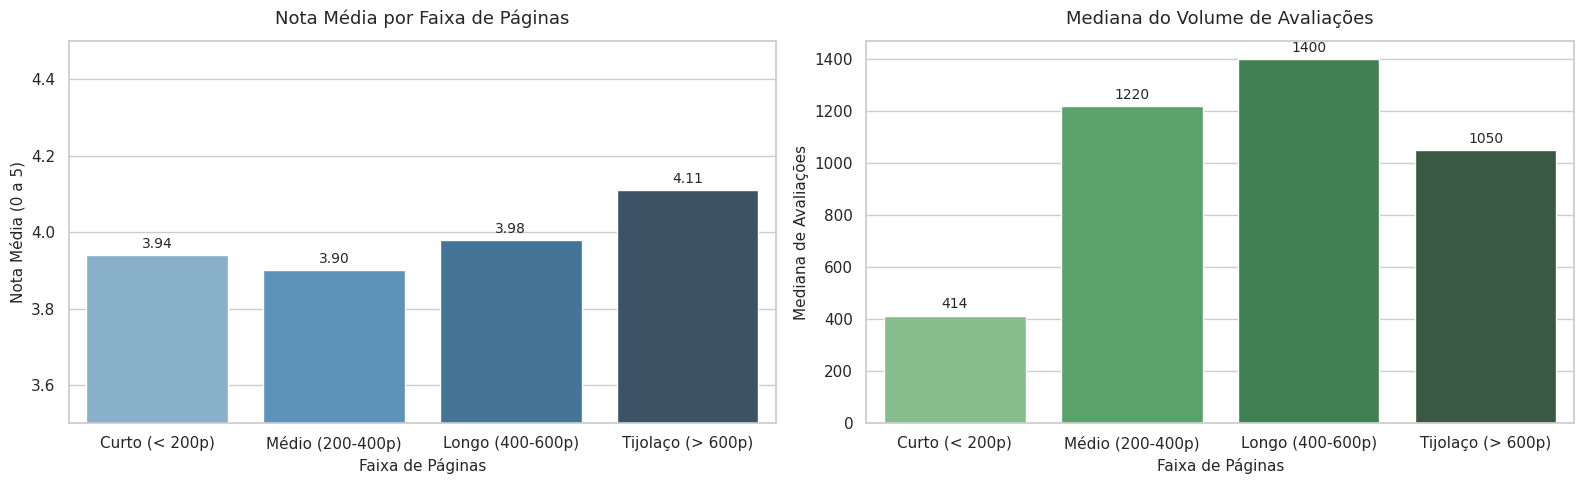

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo visual global
sns.set_theme(style="whitegrid")

# Criar a figura com 1 linha e 2 colunas
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ----------------------------------------------------
# Gráfico 1 (Esquerda): Nota Média
# ----------------------------------------------------
sns.barplot(
    data=analise_tijolaco,
    x='faixa_paginas',
    y='nota_media',
    hue='faixa_paginas',
    palette='Blues_d',
    legend=False,
    ax=axes[0]  # Direciona para o painel da esquerda
)

axes[0].set_title('Nota Média por Faixa de Páginas', fontsize=13, pad=12)
axes[0].set_xlabel('Faixa de Páginas', fontsize=11)
axes[0].set_ylabel('Nota Média (0 a 5)', fontsize=11)
axes[0].set_ylim(3.5, 4.5)

# Rótulos do Gráfico 1 (formatados com 2 casas decimais)
for container in axes[0].containers:
    labels = [f'{v.get_height():.2f}' if v.get_height() > 0 else '' for v in container]
    axes[0].bar_label(container, labels=labels, padding=3, fontsize=10)

# ----------------------------------------------------
# Gráfico 2 (Direita): Mediana do Volume de Avaliações
# ----------------------------------------------------
sns.barplot(
    data=analise_tijolaco,
    x='faixa_paginas',
    y='mediana_avaliacoes',
    hue='faixa_paginas',
    palette='Greens_d',
    legend=False,
    ax=axes[1]  # Direciona para o painel da direita
)

axes[1].set_title('Mediana do Volume de Avaliações', fontsize=13, pad=12)
axes[1].set_xlabel('Faixa de Páginas', fontsize=11)
axes[1].set_ylabel('Mediana de Avaliações', fontsize=11)

# Rótulos do Gráfico 2 (formatados como inteiros)
for container in axes[1].containers:
    labels = [f'{v.get_height():.0f}' if v.get_height() > 0 else '' for v in container]
    axes[1].bar_label(container, labels=labels, padding=3, fontsize=10)

# Ajustar espaçamento automático entre os dois gráficos
plt.tight_layout()
plt.show()

> **Insight do Painel:** A nota média apresenta crescimento constante da faixa *Curto* para a faixa *Tijolaço*. Em contrapartida, a mediana de avaliações diminui nas obras mais extensas, confirmando a existência de uma barreira de entrada para o leitor médio.